# ClimateFlow: Predicting Extreme Climate Days Across Canada

**An end-to-end data pipeline and ML project using publicly available Canadian weather records.**

Canada spans six climate zones — from Vancouver's oceanic mild winters to the continental
deep-freeze of the prairies. That diversity makes a simple question surprisingly hard to answer:
*what counts as an extreme weather day for a given city?*

ClimateFlow builds a reproducible pipeline that:
1. Fetches 20 years of daily climate observations and 30-year normals from the MSC GeoMet OGC API
2. Cleans and merges the data into SQLite
3. Engineers 25 geospatial and temporal features, including anomalies relative to 30-year baselines
4. Trains a city-specific XGBoost classifier to flag extreme temperature days
5. Visualises results on an interactive Folium map

**Key result:** F1 = 0.833 · Recall = 0.961 · ROC-AUC = 0.998 across 9 cities, 2020–2023 test period.


---
## 0. Setup

In [1]:
import sqlite3, warnings, os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Image, IFrame, display

warnings.filterwarnings("ignore")

# Locate project root regardless of where the kernel was launched from.
# Walks up from CWD until it finds the directory that contains 'pipeline/'.
PROJ = Path.cwd()
while not (PROJ / "pipeline").exists() and PROJ != PROJ.parent:
    PROJ = PROJ.parent

DB    = PROJ / "data/processed/climateflow.db"
PLOTS = PROJ / "outputs/plots"
MAPS  = PROJ / "outputs/maps"

print(f"Project root: {PROJ}")
print(f"Database    : {DB}  (exists: {DB.exists()})")

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 120})

def load(table):
    conn = sqlite3.connect(DB)
    df = pd.read_sql(f"SELECT * FROM {table}", conn)
    conn.close()
    return df


Project root: /mnt/c/NavitComputer24/01 NavitComputer2016/DIARY 2026/Jobs 2026/26 06 10 Esri Data Specialist/climateflow
Database    : /mnt/c/NavitComputer24/01 NavitComputer2016/DIARY 2026/Jobs 2026/26 06 10 Esri Data Specialist/climateflow/data/processed/climateflow.db  (exists: True)


---
## 1. The Data

All data is fetched programmatically from Canada's
[MSC GeoMet OGC API](https://api.weather.gc.ca/collections) — no manual downloads required.

| Dataset | API endpoint | What it contains |
|---|---|---|
| Daily observations | `climate-daily` | MAX/MIN/MEAN temperature, precipitation, snow depth, humidity, wind gust |
| Climate normals | `climate-normals` | 30-year monthly averages (1981–2010) — the climatological baseline |
| Station metadata | `climate-stations` | Coordinates and elevation for 8,614 stations across Canada |

**Nine cities were selected** to span Canada's main climate regions:
Vancouver (oceanic), Calgary and Edmonton (semi-arid continental), Saskatoon and Winnipeg
(cold continental), Toronto and Ottawa (humid continental), Montréal and Québec City
(humid continental / maritime).

Halifax was excluded: its primary daily station had 100% null temperatures throughout the
2020–2023 test period, making it impossible to evaluate the model there.


In [2]:
df = load("climate_daily_clean")
df["LOCAL_DATE"] = pd.to_datetime(df["LOCAL_DATE"])

print(f"Shape      : {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Date range : {df['LOCAL_DATE'].min().date()} → {df['LOCAL_DATE'].max().date()}")
print(f"Cities     : {sorted(df['city'].unique())}")


Shape      : 64,734 rows × 31 columns
Date range : 2004-01-01 → 2023-12-31
Cities     : ['Calgary', 'Edmonton', 'Montreal', 'Ottawa', 'Quebec', 'Saskatoon', 'Toronto', 'Vancouver', 'Winnipeg']


In [3]:
coverage = (
    df.groupby(["city", "province"])
    .agg(
        from_year=("LOCAL_DATE", lambda s: s.min().year),
        to_year  =("LOCAL_DATE", lambda s: s.max().year),
        n_days   =("LOCAL_DATE", "count"),
        lat      =("lat",  "first"),
        lon      =("lon",  "first"),
    )
    .reset_index()
    .sort_values("lon")
    .rename(columns={"from_year": "from", "to_year": "to"})
)
coverage.style.hide(axis="index").format({"lat": "{:.2f}", "lon": "{:.2f}"})


city,province,from,to,n_days,lat,lon
Vancouver,BC,2004,2023,7129,49.30,-123.12
Calgary,AB,2004,2023,6850,51.11,-114.00
Edmonton,AB,2004,2023,7271,53.57,-113.52
Saskatoon,SK,2004,2023,7294,51.48,-107.05
Winnipeg,MB,2004,2023,7281,49.89,-97.13
Toronto,ON,2004,2023,7303,43.67,-79.40
Ottawa,ON,2004,2023,7221,45.38,-75.72
Montreal,QC,2004,2023,7275,45.50,-73.58
Quebec,QC,2004,2023,7110,46.84,-71.20


---
## 2. Exploratory Analysis

### 2.1 Temperature range across cities

The box plots below show the full distribution of daily mean temperature per city.
The spread immediately shows why a fixed national threshold (e.g., flag any day where
MAX > 30°C or MIN < −20°C) would produce inconsistent results: a −30°C day in Vancouver
is a once-in-a-generation event; in Winnipeg, it happens most winters.


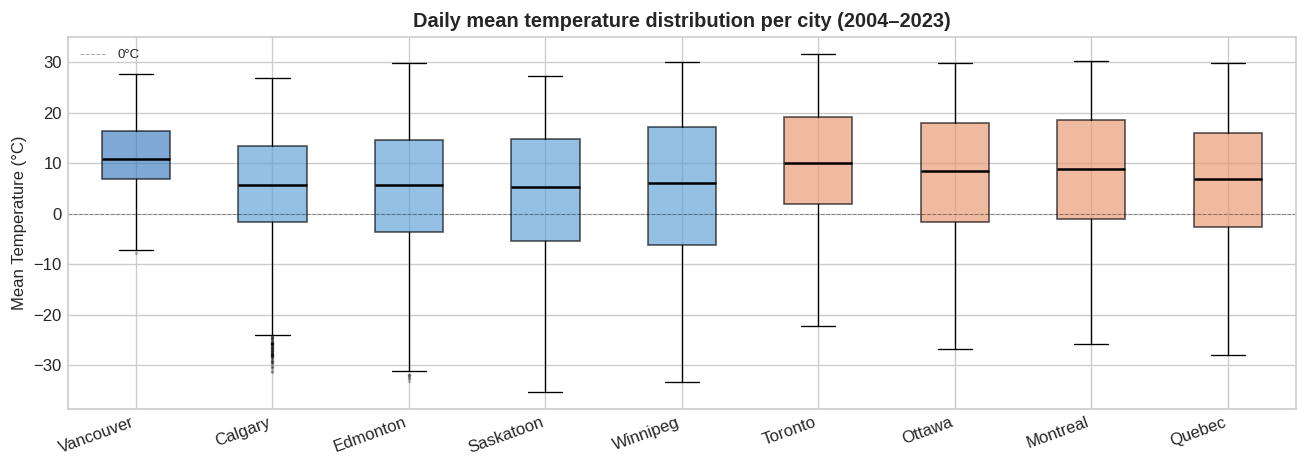

In [4]:
city_order = ["Vancouver", "Calgary", "Edmonton", "Saskatoon", "Winnipeg",
              "Toronto", "Ottawa", "Montreal", "Quebec"]

fig, ax = plt.subplots(figsize=(11, 4))
data = [df[df["city"] == c]["MEAN_TEMPERATURE"].dropna().values for c in city_order]

bp = ax.boxplot(
    data, patch_artist=True,
    medianprops =dict(color="black", linewidth=1.5),
    whiskerprops=dict(linewidth=0.8),
    capprops    =dict(linewidth=0.8),
    flierprops  =dict(marker=".", markersize=2, alpha=0.25),
)
palette = ["#3a7abf"] + ["#5a9fd4"] * 4 + ["#e8956d"] * 4
for patch, color in zip(bp["boxes"], palette):
    patch.set_facecolor(color)
    patch.set_alpha(0.65)

ax.set_xticks(range(1, len(city_order) + 1))
ax.set_xticklabels(city_order, rotation=20, ha="right")
ax.set_ylabel("Mean Temperature (°C)")
ax.set_title("Daily mean temperature distribution per city (2004–2023)", fontweight="bold")
ax.axhline(0, color="black", linewidth=0.6, linestyle="--", alpha=0.35, label="0°C")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


### 2.2 Data quality and missingness

Two columns required specific attention before modelling.

**SNOW_ON_GROUND (64% null)** — nulls here are not missing data in the conventional sense.
Environment Canada stations only report snow depth when snow is present; no report means no snow.
Imputing with 0 is the correct domain decision, not a statistical workaround.

**Temperature columns (~6% null)** — short gaps caused by station maintenance.
These are filled by forward-propagating the last valid reading within each city, capped at 7 days.
Gaps longer than 7 days remain null and are excluded from model training.


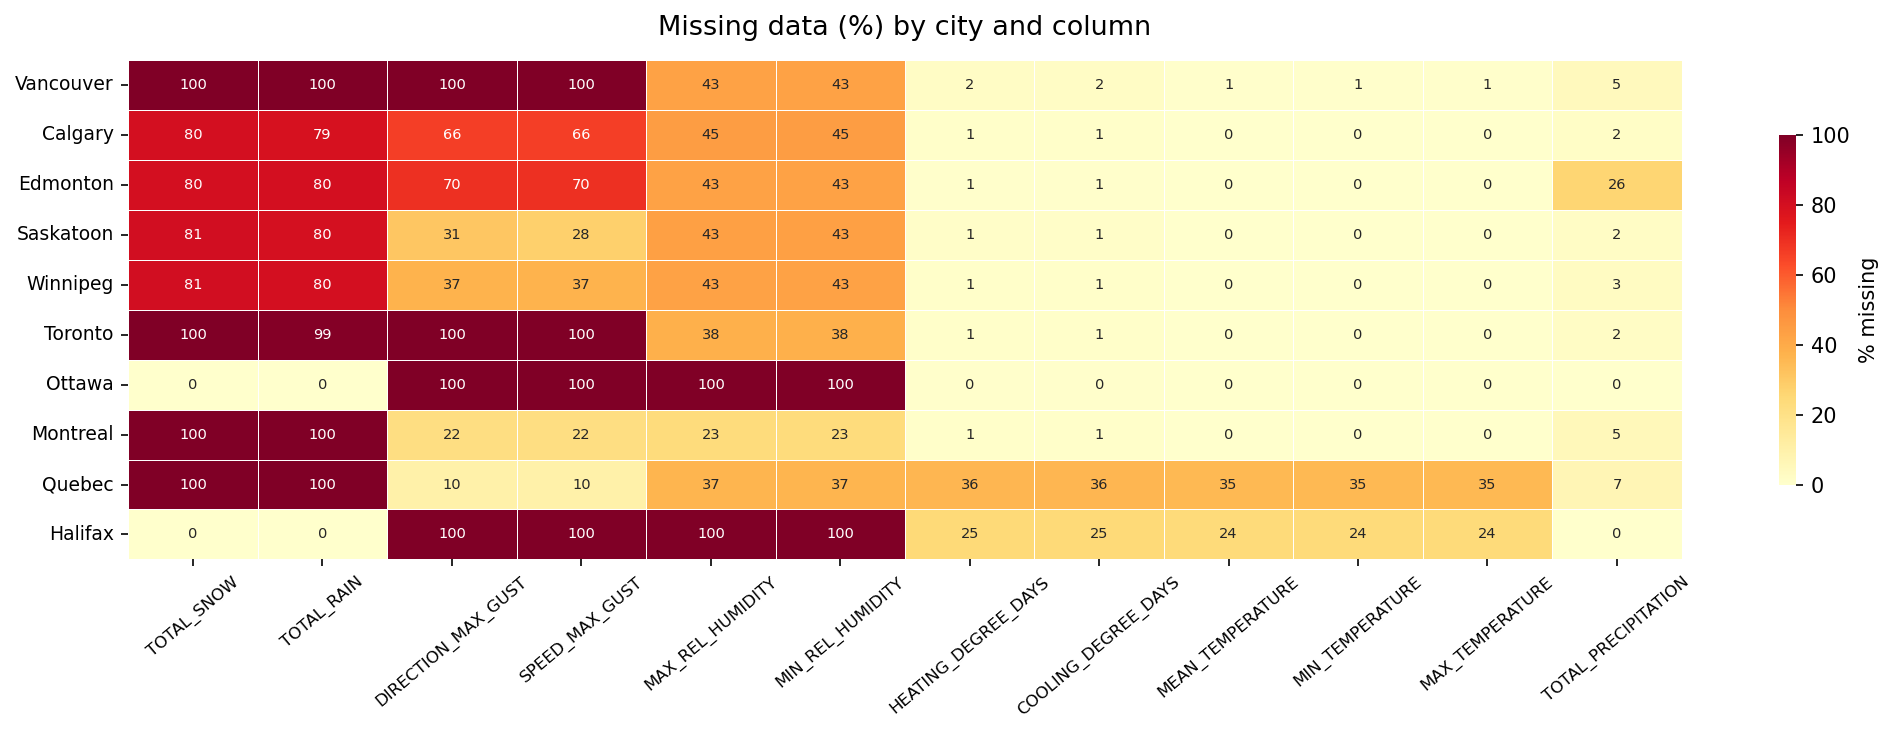

In [5]:
display(Image(PLOTS / "missingness_heatmap.png", width=820))


### 2.3 Climate normals as a baseline

The 30-year climate normals (1981–2010) provide the climatological expected value for each
city and month. Comparing observed temperatures to these baselines is more informative than
looking at raw values: a mean of 5°C in January signals a warm spell; in July, a cold snap.

This framing — *how anomalous is today relative to the long-run normal?* — is the foundation
of the feature engineering in Section 4.


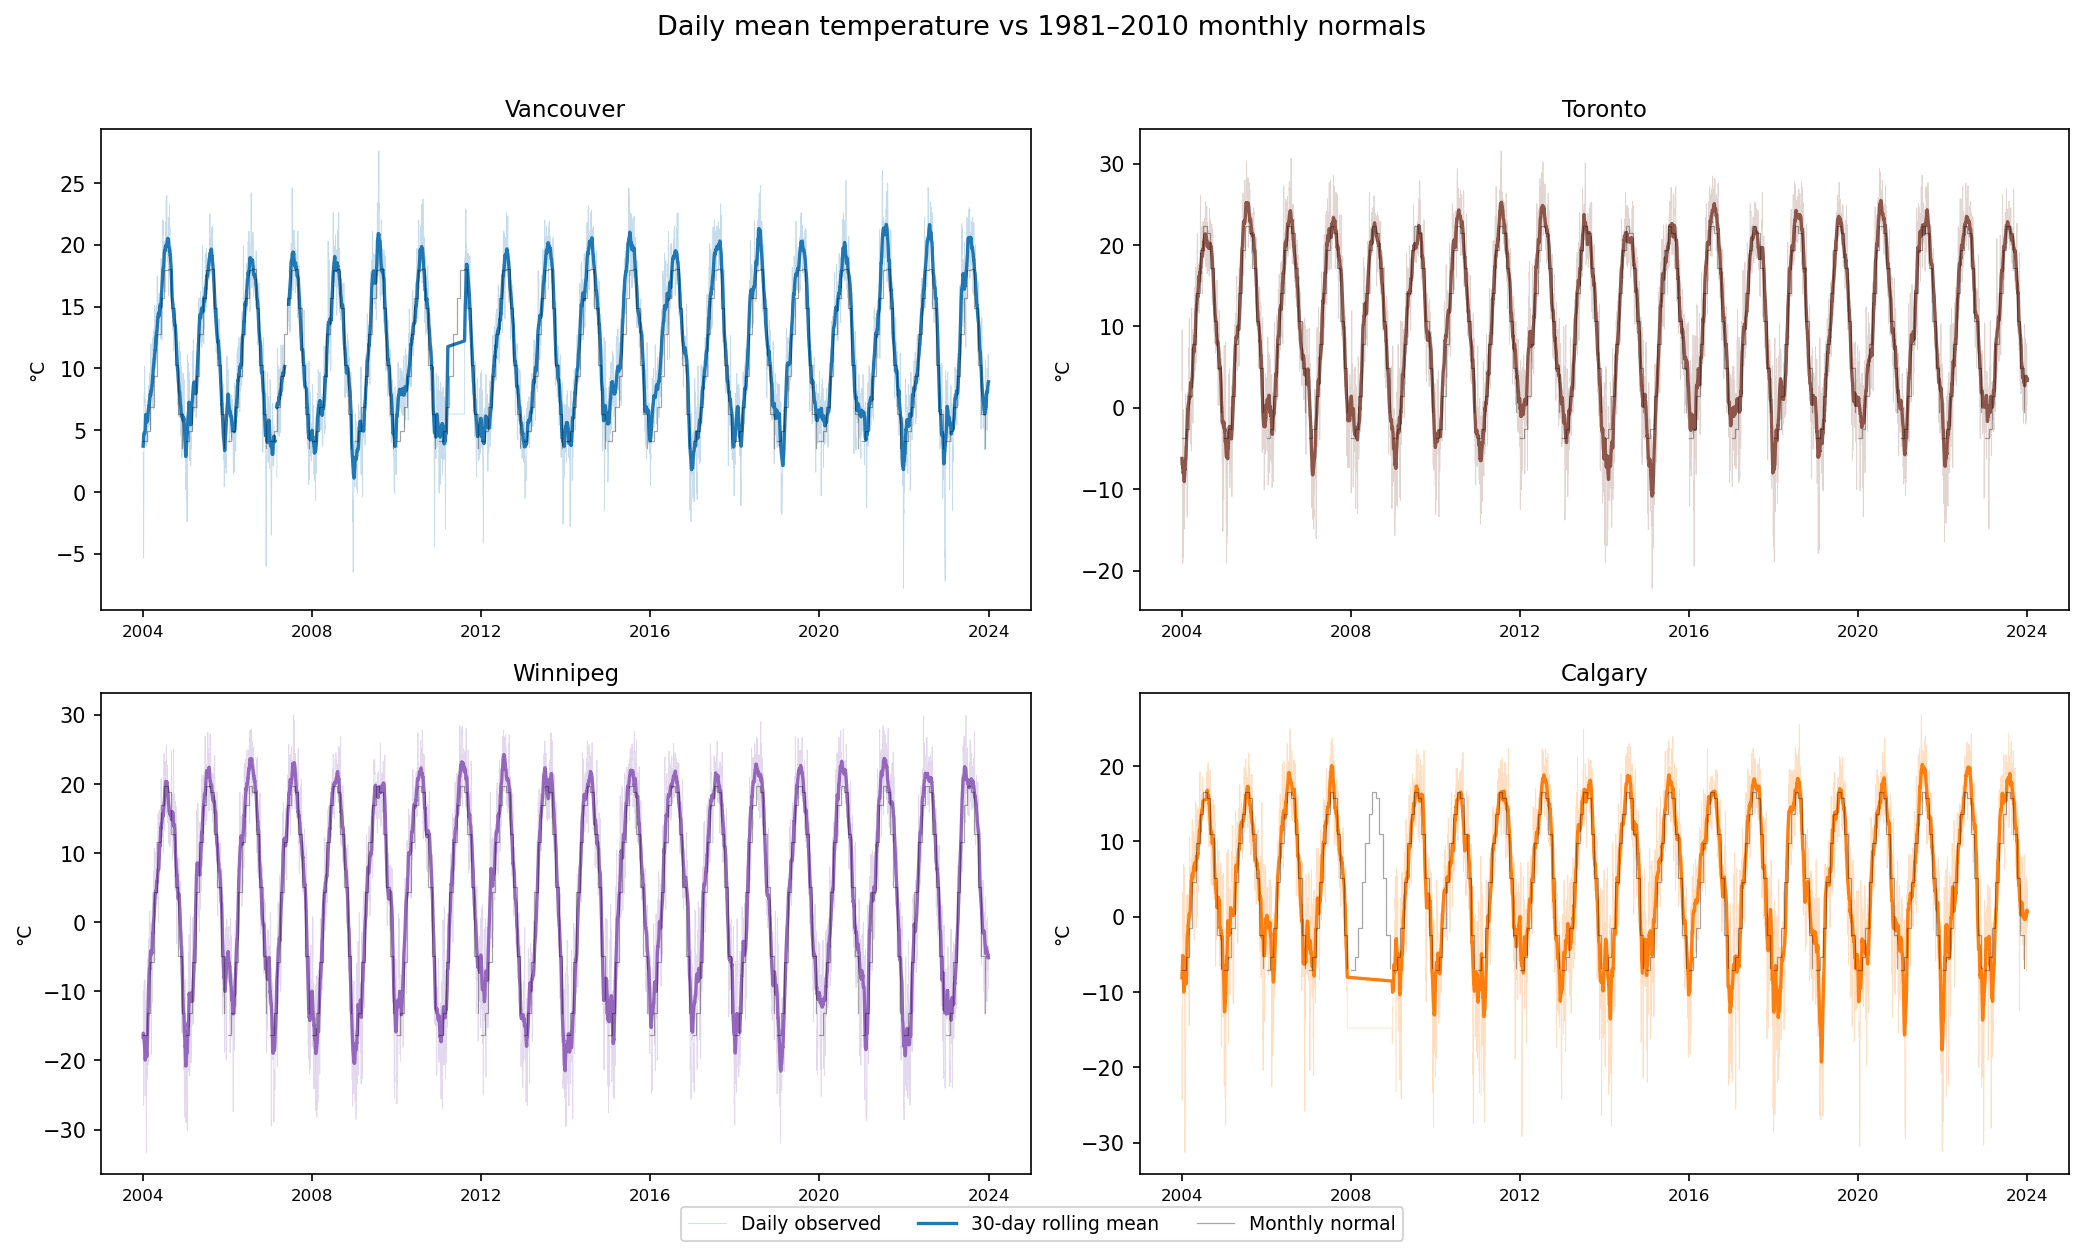

In [6]:
display(Image(PLOTS / "temperature_normals.png", width=820))


---
## 3. Cleaning Decisions

Each decision in `pipeline/clean.py` has a domain rationale, not just a statistical one.

| Decision | Rationale |
|---|---|
| Impute `SNOW_ON_GROUND` nulls → 0 | Null means no snow reported (see §2.2) |
| Forward-fill temperature gaps ≤ 7 days per city | Short maintenance gaps; longer gaps left null |
| Drop 14 `_FLAG` columns | Internal EC quality codes, not useful for modelling |
| Nullify rows where MAX_TEMP < MIN_TEMP | Data entry errors (14 rows); safer to exclude |
| Exclude Halifax | 100% null temperatures in 2020–2023 — no test-period ground truth |

The forward-fill is applied **within each city separately** and uses a 7-day limit.
Without the per-city grouping, a gap at a city boundary could fill across cities.
Without the 7-day cap, extended outages (e.g., station decommissioning) would silently
propagate stale values rather than producing visible nulls.


In [7]:
# Confirm null rates after cleaning
temp_cols = ["MEAN_TEMPERATURE", "MIN_TEMPERATURE", "MAX_TEMPERATURE"]
null_after = df[temp_cols].isnull().mean().mul(100).rename("null % after cleaning")
null_before = pd.Series({"MEAN_TEMPERATURE": 6.0, "MIN_TEMPERATURE": 6.0,
                          "MAX_TEMPERATURE": 6.0}, name="null % before cleaning (approx)")
pd.concat([null_before, null_after], axis=1).round(2)


,null % before cleaning (approx),null % after cleaning
MEAN_TEMPERATURE,6.0,3.98
MIN_TEMPERATURE,6.0,3.97
MAX_TEMPERATURE,6.0,3.97


---
## 4. Feature Engineering

`pipeline/features.py` engineers 25 model-ready features across four families.

**Anomaly features** — how far is today from what is historically expected?
`temp_relative = MEAN_TEMPERATURE − NORMAL_MEAN_TEMP` measures the departure from
the 30-year normal for that city and month. Separate anomalies are computed for MAX and MIN.

**Memory features** — weather has momentum.
A cold snap doesn't appear from nowhere. `temp_lag_1/2/3` (yesterday, two days ago, three days ago)
and `temp_roll_5/7` (5- and 7-day rolling means) give the model the recent temperature trajectory,
which is often as predictive as today's reading.

**Calendar features** — timing shapes meaning.
`day_of_year`, `month`, and `season` let the model learn that a −10°C reading in January
is unremarkable but the same value in May is a genuine anomaly.

**Rainy season** — a city-specific binary flag derived from each city's own climate normals.
Months where normal precipitation exceeds the city's annual monthly average are marked 1.
This is computed from normals only — no leakage from observed daily values.


In [8]:
feat = load("climate_features")
feat["LOCAL_DATE"] = pd.to_datetime(feat["LOCAL_DATE"])

print(f"Feature table: {len(feat):,} rows × {feat.shape[1]} columns")
print()

engineered = [
    "temp_relative", "temp_max_relative", "temp_min_relative", "precip_relative",
    "temp_lag_1", "temp_lag_2", "temp_lag_3",
    "temp_roll_5", "temp_roll_7", "precip_roll_7",
    "temp_range", "snow_present",
    "day_of_year", "month", "season", "rainy_season",
]
null_rates = feat[engineered].isnull().mean().mul(100).round(1).rename("null %")
print(null_rates.to_string())


Feature table: 64,734 rows × 31 columns

temp_relative        4.0
temp_max_relative    4.0
temp_min_relative    4.0
precip_relative      5.8
temp_lag_1           4.1
temp_lag_2           4.2
temp_lag_3           4.3
temp_roll_5          4.1
temp_roll_7          4.2
precip_roll_7        4.9
temp_range           4.0
snow_present         0.0
day_of_year          0.0
month                0.0
season               0.0
rainy_season         0.0


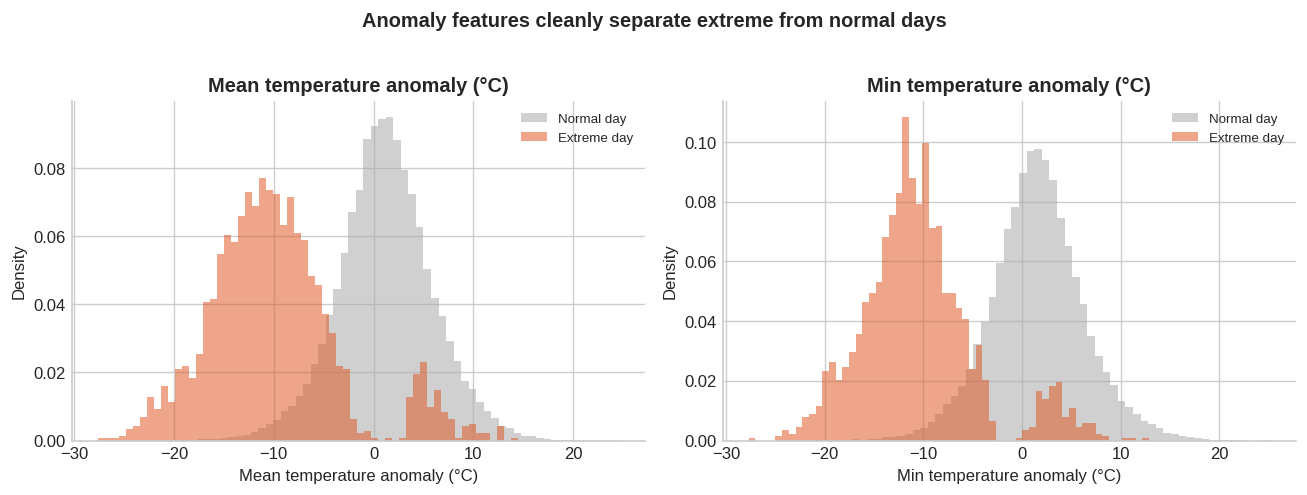

In [9]:
# Do anomaly features actually separate extreme from normal days?
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, col, title in zip(axes,
    ["temp_relative", "temp_min_relative"],
    ["Mean temperature anomaly (°C)", "Min temperature anomaly (°C)"],
):
    for val, color, label in [
        (0.0, "#aaaaaa", "Normal day"),
        (1.0, "#e05c2b", "Extreme day"),
    ]:
        vals = feat[feat["is_extreme_day"] == val][col].dropna()
        ax.hist(vals, bins=60, alpha=0.55, color=color, label=label, density=True)
    ax.set_xlabel(title)
    ax.set_ylabel("Density")
    ax.set_title(title, fontweight="bold")
    ax.legend(fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Anomaly features cleanly separate extreme from normal days", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


---
## 5. Defining "Extreme"

### Why not a fixed national threshold?

The intuitive approach — flag any day where MAX > 30°C or MIN < −20°C — fails for Canada
because its climate zones are too diverse:

- MAX = 28°C in Vancouver (July normal: 22°C) is hotter than almost any day on record there
- MIN = −22°C in Winnipeg (January normal: −16°C) is cold but unremarkable

Applying the same numbers across all cities would over-flag prairie winters and under-flag
coastal heat events.

### City-specific 2σ thresholds

Extreme days are instead defined **relative to each city's own training-period distribution**:

$$\text{warm fence} = \overline{\text{MAX}} + 2\sigma_{\text{MAX}} \qquad
  \text{cold fence} = \overline{\text{MIN}} - 2\sigma_{\text{MIN}}$$

Both statistics are computed **from the training period only** (2004–2019) to prevent the
target variable from being contaminated by test-period data.

A day is labelled extreme if `MAX_TEMPERATURE > warm_fence` **or** `MIN_TEMPERATURE < cold_fence`.


In [10]:
thr = load("city_thresholds").sort_values("upper_fence", ascending=False)
thr = thr.rename(columns={"upper_fence": "warm fence (°C)", "lower_fence": "cold fence (°C)"})
thr.style.hide(axis="index").format(precision=1)


city,warm fence (°C),cold fence (°C)
Winnipeg,38.5,-27.0
Ottawa,37.2,-20.8
Saskatoon,37.2,-26.3
Montreal,36.4,-18.9
Toronto,35.5,-13.9
Edmonton,34.6,-22.9
Quebec,34.4,-20.9
Calgary,33.9,-21.1
Vancouver,27.7,-1.9


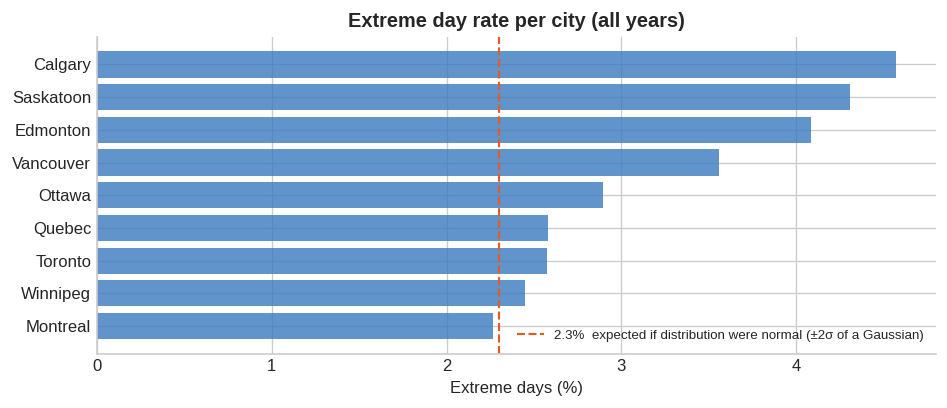

           extreme days  total days    %
city                                    
Montreal          165.0        7275  2.3
Winnipeg          178.0        7277  2.4
Toronto           188.0        7303  2.6
Quebec            119.0        4608  2.6
Ottawa            209.0        7219  2.9
Vancouver         252.0        7082  3.6
Edmonton          297.0        7271  4.1
Saskatoon         314.0        7290  4.3
Calgary           313.0        6847  4.6


In [11]:
rates = (
    feat.groupby("city")["is_extreme_day"]
    .agg(extreme="sum", total="count")
    .assign(pct=lambda d: d["extreme"] / d["total"] * 100)
    .sort_values("pct", ascending=True)
)

fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.barh(rates.index, rates["pct"], color="#3a7abf", alpha=0.8)
ax.axvline(2.3, color="#e05c2b", linewidth=1.3, linestyle="--",
           label="2.3%  expected if distribution were normal (±2σ of a Gaussian)")
ax.set_xlabel("Extreme days (%)")
ax.set_title("Extreme day rate per city (all years)", fontweight="bold")
ax.legend(fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(rates[["extreme", "total", "pct"]].rename(
    columns={"extreme": "extreme days", "total": "total days", "pct": "%"}).round(1).to_string())


---
## 6. Modelling

### Algorithm: XGBoost

Three properties made XGBoost the right choice for this problem:

1. **Class imbalance tolerance.** Extreme days are ~3% of the dataset. Gradient boosted trees
   handle imbalanced targets without resampling — they iteratively focus on misclassified
   minority examples.

2. **Non-linear interactions.** Whether a temperature anomaly constitutes an extreme day
   depends on city, season, and recent trajectory simultaneously. Trees capture these
   multi-way interactions naturally; a linear model would need them specified manually.

3. **Interpretable feature importance.** Gain-based importance gives a clear post-hoc
   explanation of which features drove decisions — essential for communicating results
   beyond a technical audience.

### The train/test split

The split is **temporal**, not random:

| Set | Years | Days |
|---|---|---|
| Train | 2004–2019 | ~46,000 |
| Test | 2020–2023 | ~12,000 |

A random split would leak future data into training — a model that saw 2022 observations during
training would appear to generalise but would fail in deployment. The forward split simulates
real operational use: learn from history, predict the future.


In [12]:
train = feat[feat["LOCAL_YEAR"] <= 2019]
test  = feat[feat["LOCAL_YEAR"] >= 2020]

print(f"Train: {len(train):,} days  |  extreme rate: {train['is_extreme_day'].mean():.2%}")
print(f"Test : {len(test):,} days  |  extreme rate: {test['is_extreme_day'].mean():.2%}")


Train: 51,709 days  |  extreme rate: 3.29%
Test : 13,025 days  |  extreme rate: 3.23%


In [13]:
metrics = pd.read_csv(PROJ / "outputs/metrics_by_city.csv")

overall = pd.DataFrame([{
    "city": "Overall (macro avg)", "n_total": metrics["n_total"].sum(),
    "n_extreme": metrics["n_extreme"].sum(),
    "f1": 0.833, "precision": 0.782, "recall": 0.961, "roc_auc": 0.998,
}])
display_df = pd.concat([metrics, overall], ignore_index=True)
display_df = display_df.rename(columns={
    "city": "City", "n_total": "Test days", "n_extreme": "Extreme days",
    "f1": "F1", "precision": "Precision", "recall": "Recall", "roc_auc": "ROC-AUC",
})

(display_df.style
    .hide(axis="index")
    .format({
        "F1": "{:.3f}", "Precision": "{:.3f}", "Recall": "{:.3f}", "ROC-AUC": "{:.4f}",
        "Test days": "{:,}", "Extreme days": "{:,}",
    })
    .apply(lambda row: [
        "font-weight: bold; background-color: #f0f4ff" if row["City"].startswith("Overall") else ""
        for _ in row
    ], axis=1)
)


City,Test days,Extreme days,F1,Precision,Recall,ROC-AUC
Vancouver,"1,456",68,0.926,0.926,0.926,0.9985
Calgary,"1,461",76,0.878,0.818,0.947,0.9984
Edmonton,"1,429",69,0.825,0.725,0.957,0.9983
Saskatoon,"1,454",72,0.814,0.716,0.944,0.9972
Winnipeg,"1,456",37,0.892,0.804,1.000,1.0000
Toronto,"1,461",20,0.691,0.543,0.950,0.9988
Ottawa,"1,387",25,0.806,0.676,1.000,0.9996
Montreal,"1,458",20,0.947,1.000,0.900,0.9990
Quebec,"1,181",24,0.906,0.828,1.000,0.9999
Overall (macro avg),"12,743",411,0.833,0.782,0.961,0.9980


**Interpreting the results:**

- **Recall = 0.961** — the model catches 96% of all true extreme days. Missing only 4% of
  real events is the right trade-off for a climate-risk application where false negatives
  are more costly than false alarms.
- **ROC-AUC ≈ 1.0** across all cities — the model has near-perfect rank-ordering ability,
  consistently scoring extreme days higher than normal days regardless of the exact threshold.
- **Toronto's lower F1 (0.691)** reflects a smaller extreme-day sample (20 events in 4 years),
  making precision volatile — one extra false positive materially shifts the score.

An ablation test confirmed that including the `season` feature improved all four metrics
simultaneously — it was retained.


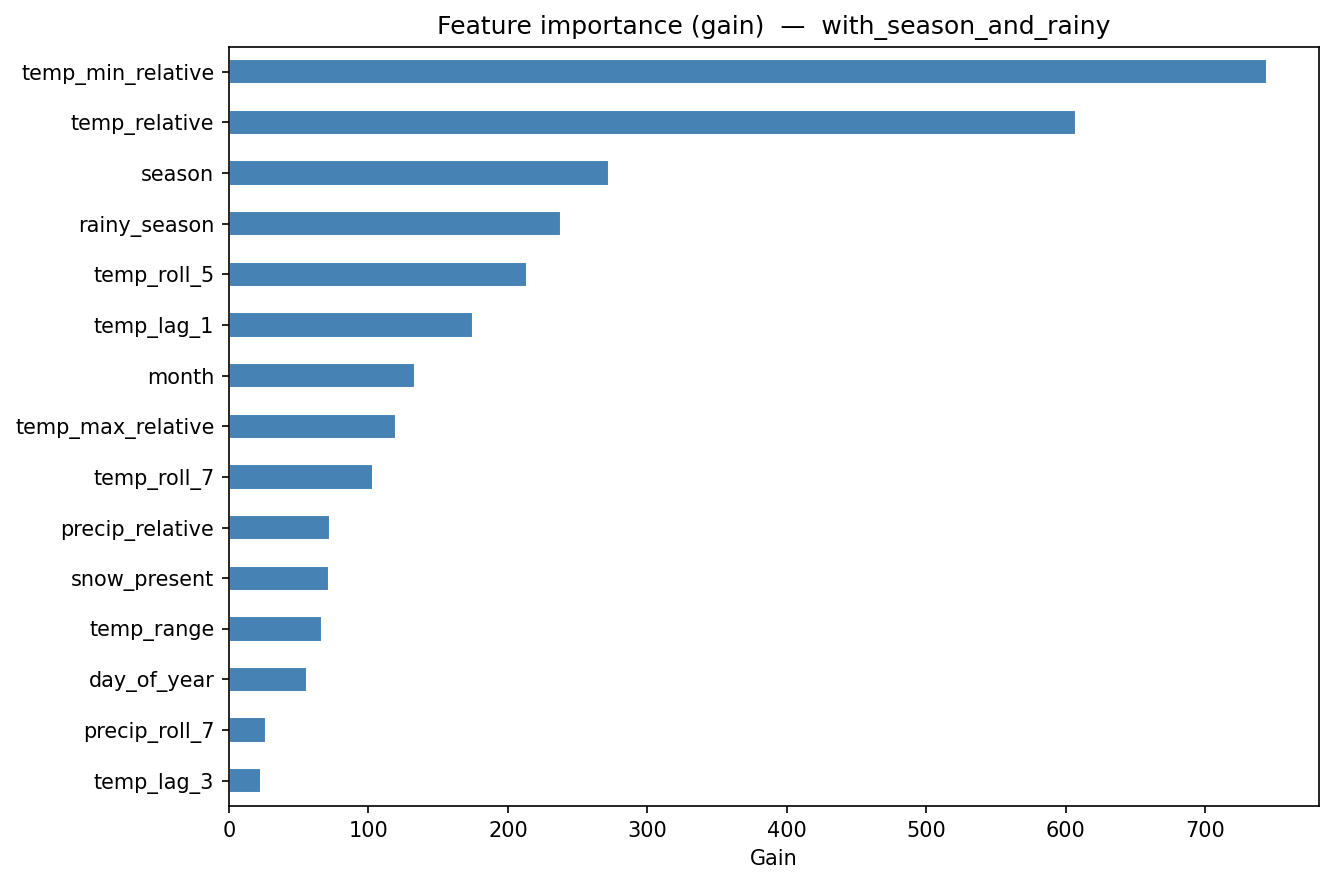

In [14]:
display(Image(PLOTS / "feature_importance.png", width=760))


`temp_min_relative` — the departure of today's minimum temperature from its 30-year normal —
is the single most important feature. This makes physical sense: cold extremes carry a
stronger and more consistent signal than warm extremes (see Section 7).

The rolling and lag features (`temp_roll_5`, `temp_lag_1`) confirm that weather trajectory
matters: knowing where temperatures have been over the past week is nearly as informative
as the current reading. Calendar features (`day_of_year`, `season`) contribute substantially,
reflecting high-risk months specific to each city.


---
## 7. Finding: Why Are There More Cold Extreme Days Than Warm?

Examining the model's predictions revealed a striking asymmetry: cold extreme days
outnumber warm extreme days by 10–100× in most Canadian cities.

The climate-change intuition — that temperatures have been trending warmer since 2000,
so more warm extremes should appear — predicts the opposite. Three checks were run:

1. **Is it the variance?** No. `std(MAX_TEMPERATURE)` is actually *larger* than `std(MIN_TEMPERATURE)`
   in every city. If distributions were symmetric, larger variance would produce *more* warm
   extremes, not fewer.

2. **Is it the thresholds?** The thresholds are ±2σ for both sides, so a symmetric Gaussian
   would produce the same ~2.3% exceedance rate on each tail.

3. **Is it the skewness?** Yes. Canadian temperature distributions are left-skewed — the cold
   tails are fatter than a Gaussian would predict. Arctic air masses produce sharp, episodic
   cold snaps that push `MIN_TEMPERATURE` well beyond the −2σ fence. Summer heat has a
   physical ceiling and dissipates more gradually, leaving the warm tail thin.

**Vancouver is the exception.** Its oceanic climate moderates both extremes, producing
near-symmetric distributions and roughly equal warm/cold extreme counts (131 vs 121 days).


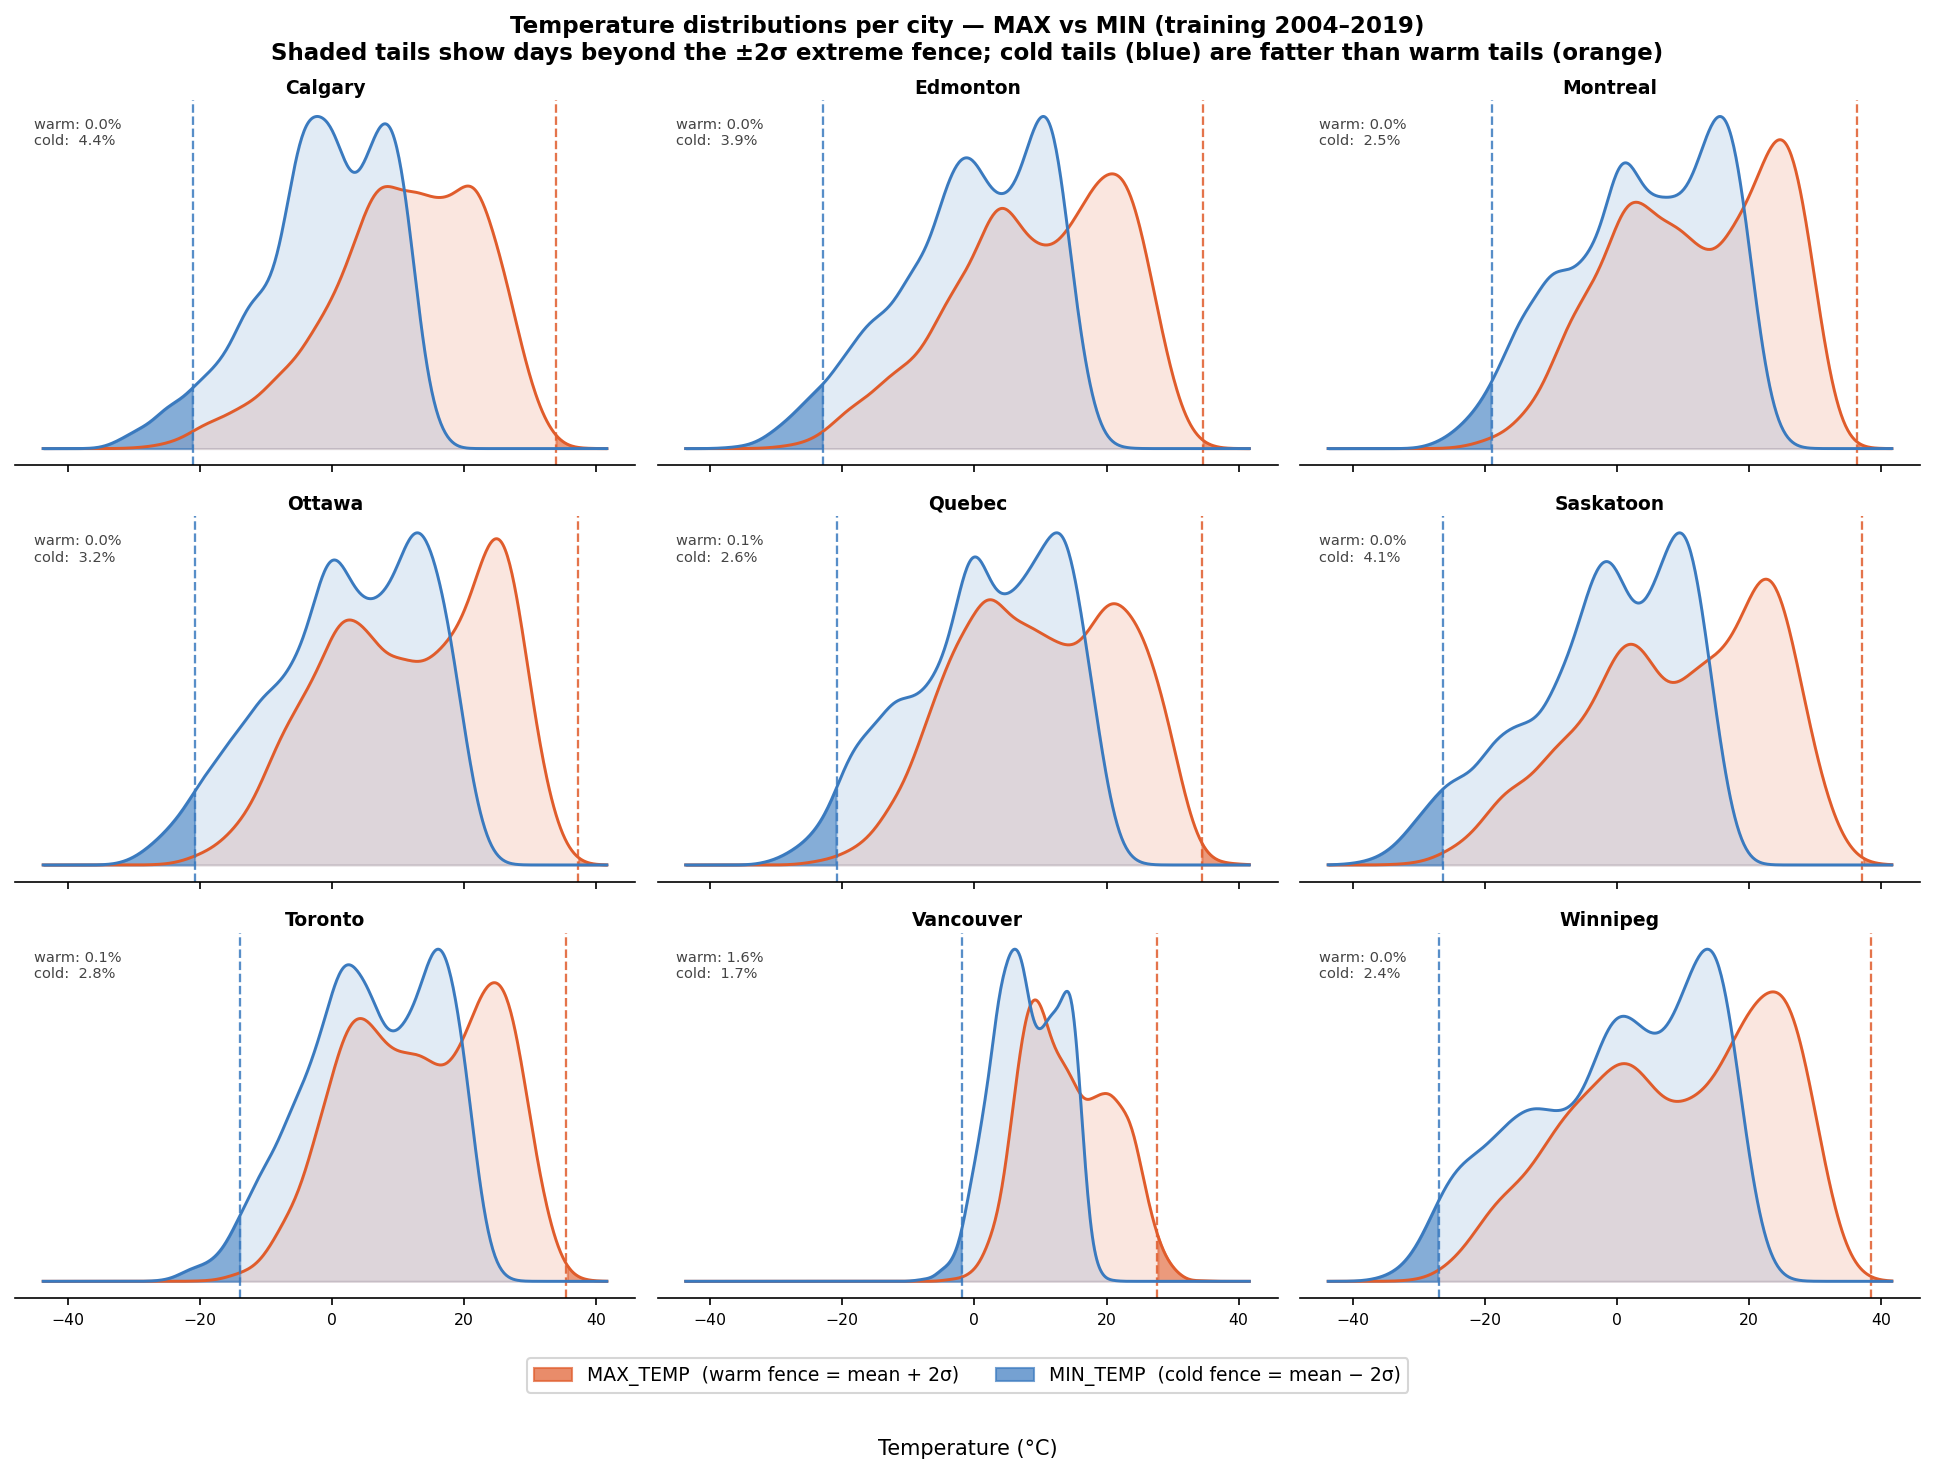

In [15]:
display(Image(PLOTS / "temperature_kde.png", width=900))


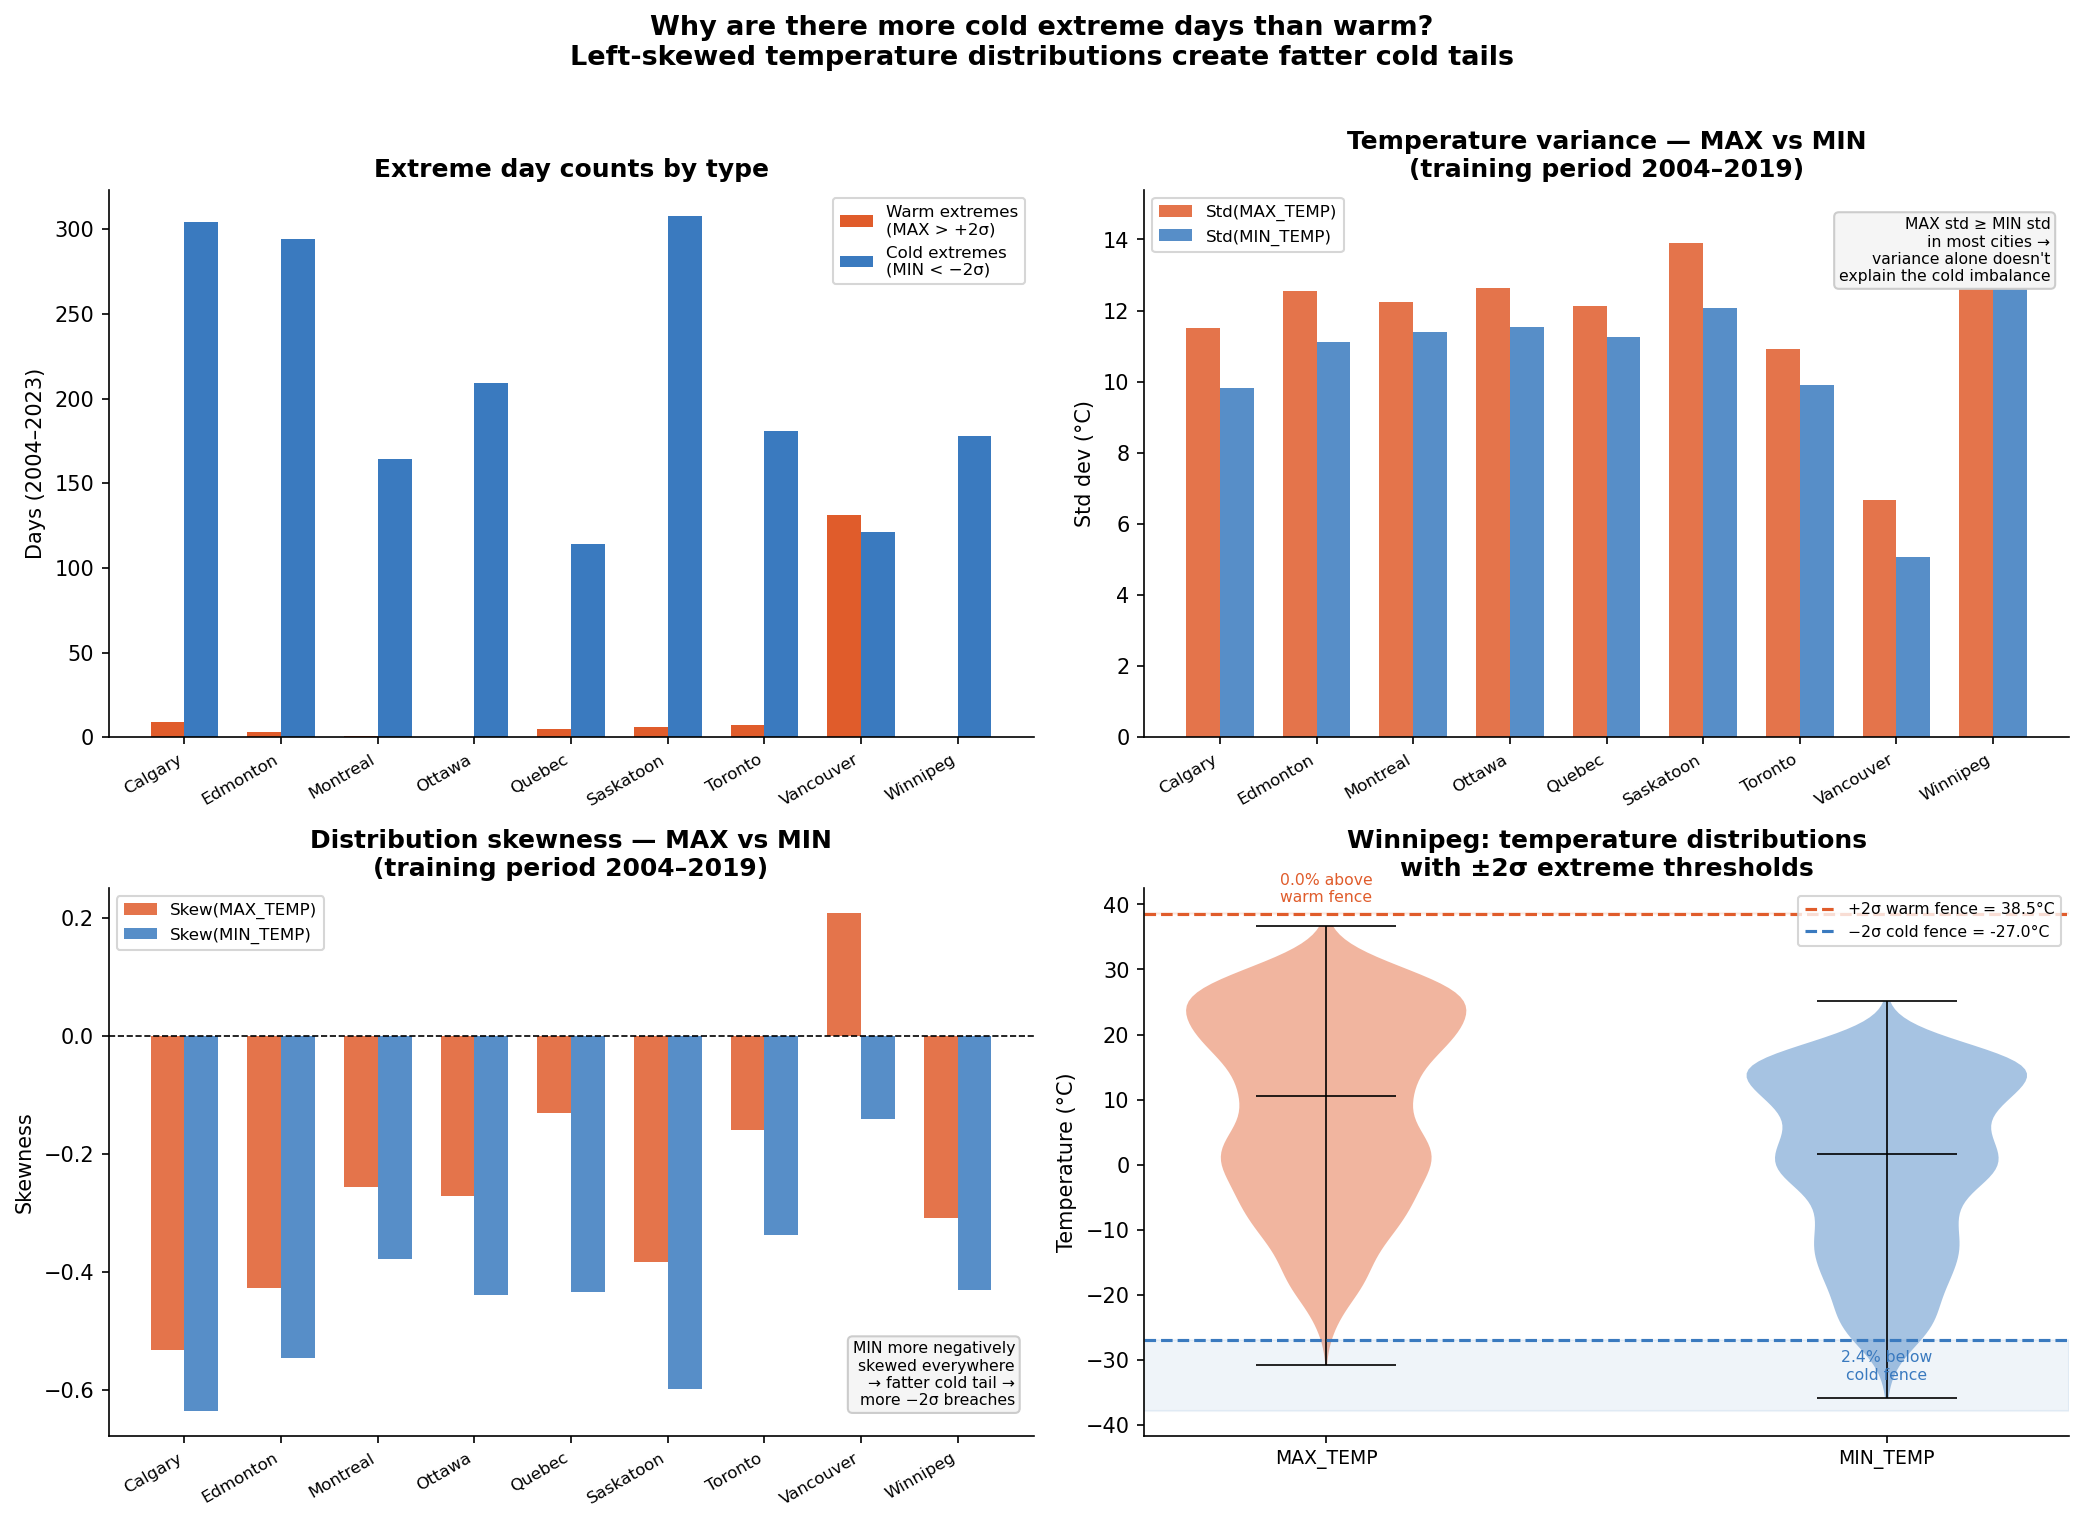

In [16]:
display(Image(PLOTS / "extreme_variance.png", width=900))


---
## 8. Interactive Map

Each marker is placed at the station coordinates, sized and coloured by the share of
test-period days flagged as extreme. Click any marker for city-level metrics.

Prairie cities (Saskatoon, Calgary, Winnipeg) anchor the high end of the scale;
Vancouver sits at the low end — consistent with the asymmetry finding above.

*If the map does not render inline, open `outputs/maps/climateflow_map.html` in a browser.*


In [17]:
IFrame(src=str(MAPS / "climateflow_map.html"), width="100%", height=520)


---
## 9. Conclusions

ClimateFlow shows that city-specific, data-driven thresholds outperform fixed national
cutoffs for defining climate extremes across a geographically diverse country like Canada.
An XGBoost classifier trained on anomaly, memory, and calendar features achieves strong
predictive performance (F1 = 0.833, ROC-AUC = 0.998) on a genuinely forward-looking
test set — no 2020–2023 data was seen during training.

The most interesting finding emerged from diagnosing the output: the dominance of cold
extreme days over warm is a structural property of Canadian temperature distributions,
not a modelling artefact. Left-skewed MIN temperatures, driven by episodic Arctic
intrusions, cause more days to breach the cold −2σ fence than summer heat breaches the
warm +2σ fence. Vancouver's symmetric oceanic climate produces the only city with
near-equal warm and cold counts — a clean natural experiment.

---

**To reproduce from scratch:**
```bash
python -m pipeline.ingest    # fetch data from MSC GeoMet API
python -m pipeline.clean     # clean, impute, merge normals → SQLite
python -m pipeline.features  # engineer 25 features
python -m models.forecast    # train XGBoost, save outputs
python -m viz.map            # interactive map + plots
```

**Repository:** https://github.com/navitd/climateflow
**Data:** Environment and Climate Change Canada — MSC GeoMet OGC API (open licence)
